# AI SCI 290A Project 1: Weather Prediction
Using ERA5 data to answer the question Can we predict the weather at UC Irvine?

# 1. Imports

In [243]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns
import glob
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# 2. Preliminary Exploration

In [244]:
DATA_DIR = "./data/"

In [245]:
temp_files = sorted(
    glob.glob(f"{DATA_DIR}/**/*.nc", recursive=True)
)
ds = xr.open_mfdataset(
    temp_files,
    combine="by_coords"
)

## Avg temp

Text(0.5, 1.0, 'Mean 2m temp')

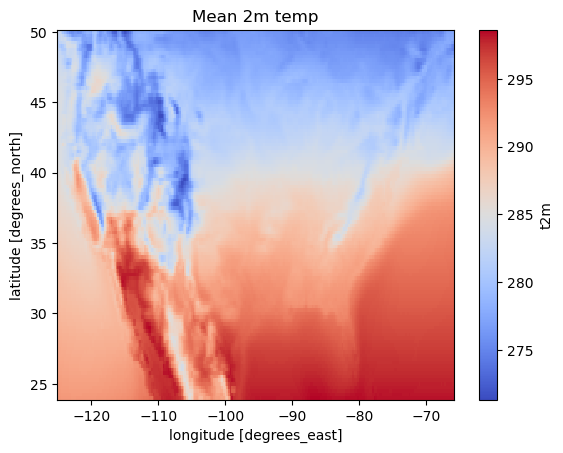

In [246]:
fig, ax = plt.subplots()
ds.t2m.mean(dim="valid_time").plot(cmap="coolwarm")
ax.set_title("Mean 2m temp")

## Temperature over time at UC Irvine

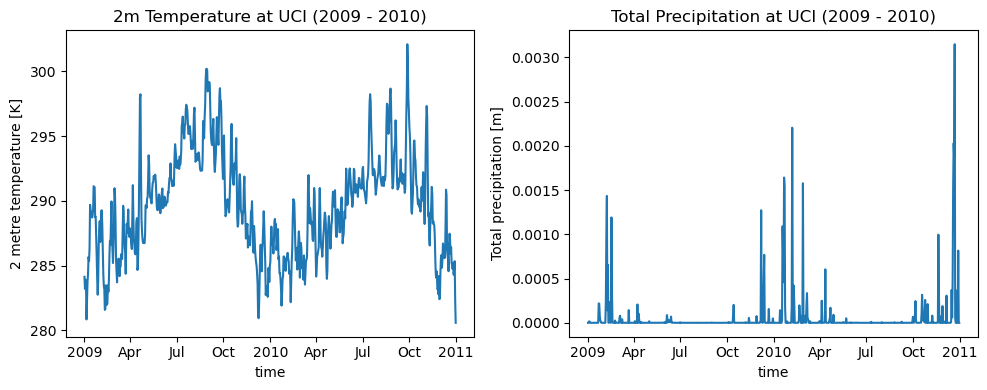

In [247]:
lat_uci = 33.64
lon_uci = -117.84

ds_uci = ds.sel(latitude=lat_uci, longitude=lon_uci, method="nearest")

fig, axs = plt.subplots(
    ncols=2,
    figsize=(10, 4)
)
ds_uci.t2m.plot(ax=axs[0])
axs[0].set_title("2m Temperature at UCI (2009 - 2010)")

ds_uci.tp.plot(ax=axs[1])
axs[1].set_title("Total Precipitation at UCI (2009 - 2010)")

fig.tight_layout()

## Feature Engineering

In [248]:
ds_uci["t2m"] = ds_uci["t2m"]-273.15

In [249]:
# Calcs and adds 3 and 7 day rolling average and previous day columns
ds_uci['rolling_3'] = ds_uci['t2m'].rolling(valid_time=3).mean()  # up to yesterday
ds_uci['rolling_7'] = ds_uci['t2m'].rolling(valid_time=7).mean()
ds_uci["target_t2m"] = ds_uci["t2m"].shift(valid_time=-1)

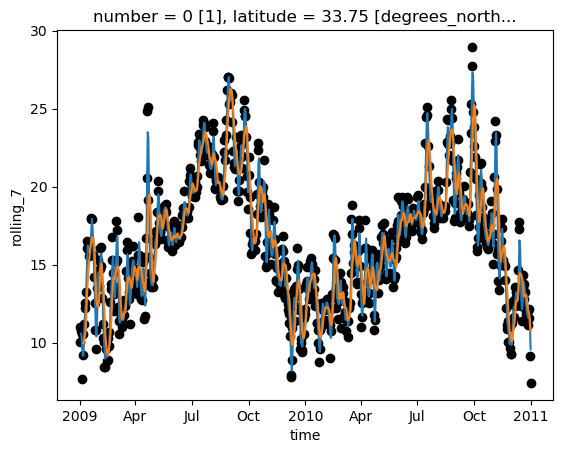

In [250]:
fig, ax = plt.subplots()

ds_uci["t2m"].plot.scatter("valid_time", color="black")
ds_uci["rolling_3"].plot()
ds_uci["rolling_7"].plot()

# 3. Temperature

In [251]:
# Prep for regression by deleting nan rows
ds_uci = ds_uci.dropna(dim="valid_time")
n_samples = len(ds_uci["valid_time"])

# Test train split
X = ds_uci.to_dataframe()[["t2m", "rolling_3", "rolling_7"]]
y = ds_uci["target_t2m"].values

X_train, X_split, y_train, y_split = train_test_split(X, y, random_state=210, shuffle=False, test_size=0.2)

X_val, X_test, y_val, t_test = train_test_split(X_split, y_split, random_state=210, shuffle=False, test_size=0.5)


In [252]:
# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_val_sc = X_scaler.transform(X_val)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_clean = y_train.reshape(-1, 1)

y_scaler.fit(y_train_clean)
y_train_sc = y_scaler.transform(y_train_clean)
y_val_sc = y_scaler.transform(y_val.reshape(-1, 1))
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

In [253]:
# Set up metrics
reg_metrics = pd.DataFrame(columns=["model", "score", "mse"])

## Linear Regression
Predicts using a 3-day rolling average, 7-day rolling average, and the previous day's temperature.

### Predictors: Previous Day, 3-Day Rolling, and 7-Day Rolling

In [254]:
reg = LinearRegression()
reg.fit(X_train, y_train)

y_pred = reg.predict(X_val)

reg_metrics.loc[len(reg_metrics)] = {'model': 'linear_reg_3', 'score': reg.score(X_val, y_val), 'mse': mean_squared_error(y_val, y_pred)}

## Neural Network - 3 var

In [255]:
reg = MLPRegressor(
    random_state=222,
    )
reg.fit(X_train_sc, y_train_sc.ravel())

y_pred = reg.predict(X_val_sc)

y_pred = y_scaler.inverse_transform(y_pred.reshape(-1, 1))

reg_metrics.loc[len(reg_metrics)] = {'model': 'nn_3', 'score': reg.score(X_val_sc, y_val_sc), 'mse': mean_squared_error(y_val, y_pred)}

## Neural Network - all var

In [256]:
X = ds_uci.to_dataframe()[["t2m", "rolling_3", "rolling_7", "v10", "u10", "msl", "tp"]]
y = ds_uci["target_t2m"].values

X_train, X_split, y_train, y_split = train_test_split(X, y, random_state=210, shuffle=False, test_size=0.2)
X_val, X_test, y_val, y_test = train_test_split(X_split, y_split, random_state=210, shuffle=False, test_size=0.5)

# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_val_sc = X_scaler.transform(X_val)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_clean = y_train.reshape(-1, 1)

y_scaler.fit(y_train_clean)
y_train_sc = y_scaler.transform(y_train_clean)
y_val_sc = y_scaler.transform(y_val.reshape(-1, 1))
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

In [268]:
reg = MLPRegressor(
    random_state=222,
    )
reg.fit(X_train_sc, y_train_sc.ravel())

y_pred = reg.predict(X_val_sc)

y_pred = y_scaler.inverse_transform(y_pred.reshape(-1, 1))

reg_metrics.loc[len(reg_metrics)] = {'model': 'nn_a', 'score': reg.score(X_val_sc, y_val_sc), 'mse': mean_squared_error(y_val, y_pred)}

In [258]:
reg_metrics

,model,score,mse
0,linear_reg_3,0.830105,1.340581
1,nn_3,0.783194,1.710745
2,nn_a,0.803838,1.547850


<Axes: title={'center': 'MSE'}, xlabel='model', ylabel='mse'>

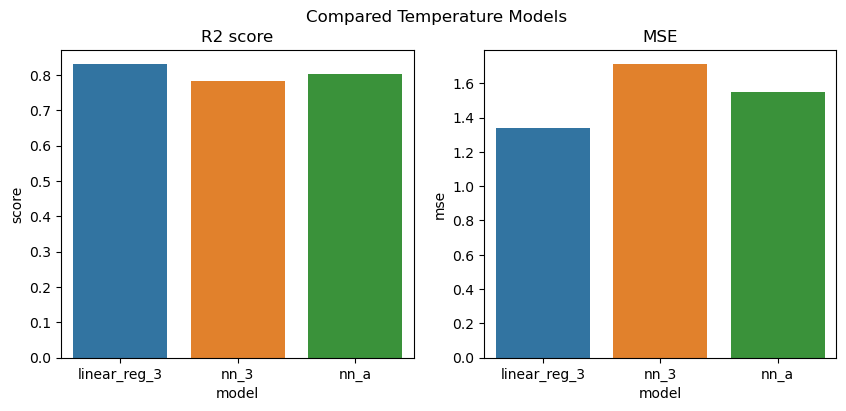

In [259]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10,4))

fig.suptitle("Compared Temperature Models")
ax[0].set_title("R2 score")
ax[1].set_title("MSE")
sns.barplot(data=reg_metrics, x="model", y="score", hue="model", ax=ax[0])
sns.barplot(data=reg_metrics, x="model", y="mse", hue="model", ax=ax[1])

# 4. Precipitation

## Feature Engineering

In [269]:
X = ds_uci[["msl", "t2m", "u10", "v10"]].to_dataframe()
y = (ds_uci["tp"].shift(valid_time=-1) > 0).values

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, random_state=222, test_size=0.15)

In [270]:
# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_clean = y_train.reshape(-1, 1)

y_scaler.fit(y_train_clean)
y_train_sc = y_scaler.transform(y_train_clean)
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

## Logistic Regression

In [ ]:
clf = LogisticRegression(max_iter=300, random_state=222)
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,222
,solver,'lbfgs'
,max_iter,300
,multi_class,'deprecated'


## Neural Network

In [273]:
clf = MLPClassifier(
    hidden_layer_sizes=(16,),
    max_iter=500,
    random_state=222,
    shuffle=False
)
clf.fit(X_train_sc, y_train)

clf.score(X_test_sc, y_test)

0.7064220183486238

## Tree

In [274]:
from sklearn.tree import DecisionTreeClassifier

clf = DecisionTreeClassifier(random_state=222)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

clf.score(X_test, y_test)

0.6513761467889908

## Random Forest

In [275]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(random_state=222)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

clf.score(X_test, y_test)

0.7798165137614679